In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [7]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2', 'mcevi']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']
df_all = getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc.root', "MatchedTree")

In [12]:
distance1 = []
distance2 = []
for i in range(0,df_all.shape[0]):
    phi1small = min(df_all.iloc[i]['phi1'], df_all.iloc[i]['phi1s'])
    phi1large = max(df_all.iloc[i]['phi1'], df_all.iloc[i]['phi1s'])
    phi2small = min(df_all.iloc[i]['phi2'], df_all.iloc[i]['phi2s'])
    phi2large = max(df_all.iloc[i]['phi2'], df_all.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_all.iloc[i]['phi1'], df_all.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_all.iloc[i]['y1']-df_all.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_all.iloc[i]['y2']-df_all.iloc[i]['y2s'])**2))
df_all['distance1'] = distance1
df_all['distance2'] = distance2

In [3]:
df_all = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc.csv', low_memory=False)
df_all

,pt,b,w,y1,y2,phi1,phi2,mcevi,pts,bs,ws,y1s,y2s,phi1s,phi2s,nefs,distance1,distance2
0,6.909035,-1,1.335866e-10,-0.566667,-0.581373,0.254736,0.123353,1,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,8.941545,8.884809
1,7.770895,-9,1.335866e-10,-9.000000,-9.000000,-9.000000,-9.000000,2,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,0.000000,0.000000
2,5.072170,1,1.335866e-10,-0.282474,-0.409867,5.993405,0.018299,4,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,12.323278,9.015056
3,7.017721,1,1.335866e-10,0.213610,-0.212909,2.084065,2.228717,7,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,10.389372,10.083217
4,10.088763,-1,1.335866e-10,0.446627,0.397990,5.020298,5.315151,8,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,12.210720,12.362633
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21473756,5.589589,-1,3.372111e-10,-0.138695,0.013598,5.879950,6.135971,30487746,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,12.346136,12.633953
21473757,5.198447,-9,3.372111e-10,-9.000000,-9.000000,-9.000000,-9.000000,30487747,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,0.000000,0.000000
21473758,12.328792,-1,3.372111e-10,-0.236462,0.165022,4.458089,4.457092,30487750,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,11.326025,11.638839
21473759,8.193869,-1,3.372111e-10,-0.508361,-0.585699,4.988478,4.940525,30487754,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,11.466449,11.376964


In [4]:
odd = []
even = []
for i in range(0, df_all.shape[0]):
    if (df_all.iloc[i]['mcevi'] % 2 == 0):
        even.append(i)
    else:
        odd.append(i)

In [5]:
df1_all = df_all.iloc[odd]
df2_all = df_all.iloc[even]
df1_all.shape[0],df2_all.shape[0]

(10735656, 10738105)

In [6]:
df1_allreco = applyCut(df1_all, 'pts>15 and bs!=-9 and w<1')
df2_allreco = applyCut(df2_all, 'pts>15 and bs!=-9 and w<1')
df1_alltruth = applyCut(df1_all, 'pt>5 and b!=-9 and w<1')
df2_alltruth = applyCut(df2_all, 'pt>5 and b!=-9 and w<1')

Process sample 1

In [7]:
df1_allfake = applyCut(df1_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df1_match = applyCut(df1_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [8]:
df1_allreco_pts_array = [ df1_allreco[(df1_allreco.pts>15) & (df1_allreco.pts<20)],\
                       df1_allreco[(df1_allreco.pts>20) & (df1_allreco.pts<25)],\
                       df1_allreco[(df1_allreco.pts>25) & (df1_allreco.pts<30)],\
                       df1_allreco[(df1_allreco.pts>30) & (df1_allreco.pts<40)],\
                       df1_allreco[(df1_allreco.pts>40) & (df1_allreco.pts<60)] ]

df1_match_pts_array = [ df1_match[(df1_match.pts>15) & (df1_match.pts<20)],\
                       df1_match[(df1_match.pts>20) & (df1_match.pts<25)],\
                       df1_match[(df1_match.pts>25) & (df1_match.pts<30)],\
                       df1_match[(df1_match.pts>30) & (df1_match.pts<40)],\
                       df1_match[(df1_match.pts>40) & (df1_match.pts<60)] ]

df1_allfake_pts_array = [ df1_allfake[(df1_allfake.pts>15) & (df1_allfake.pts<20)],\
                       df1_allfake[(df1_allfake.pts>20) & (df1_allfake.pts<25)],\
                       df1_allfake[(df1_allfake.pts>25) & (df1_allfake.pts<30)],\
                       df1_allfake[(df1_allfake.pts>30) & (df1_allfake.pts<40)],\
                       df1_allfake[(df1_allfake.pts>40) & (df1_allfake.pts<60)]  ]

In [9]:
rc1_allreco_bs_vs_pts_array = []
rc1_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df1_allreco_pts_array)):
    rc1_allreco_bs_vs_pts_array.append(getRcAndErr(df1_allreco_pts_array[i], 'bs')[0])
    rc1_err_allreco_bs_vs_pts_array.append(getRcAndErr(df1_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df1_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df1_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df1_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df1_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df1_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df1_allfake_pts_array[i], 'bs')[1])

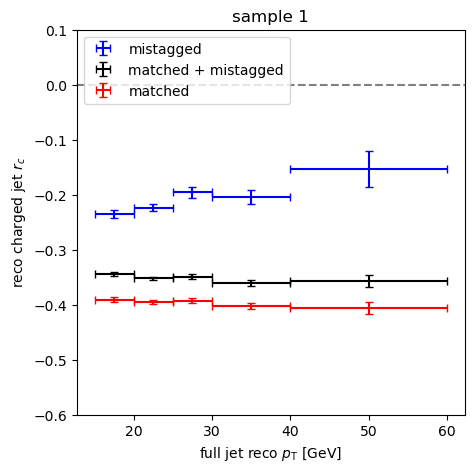

In [11]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]')
plt.title('sample 1')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [30]:
rc1_allreco_bs_vs_pts_array

[-0.34460180357509024,
 -0.35219283561963,
 -0.34888802597383506,
 -0.36056074086227397,
 -0.35678576850126065]

In [31]:
rc1_err_allreco_bs_vs_pts_array

[0.003779293928869173,
 0.0031336221547817776,
 0.004285828001538018,
 0.0053584564592269995,
 0.011365159952861609]

In [14]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [15]:
b1_fake_array = []
b1_err_fake_array = []
for i in range(0,5):
    df1_fake_pts = df1_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df1_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df1_fake_pts['ws'], density=True)
    b1_fake_array.append(y_fake_rec/sum(y_fake_rec))
    b1_err_fake_array.append(yerr_fake_rec/sum(y_fake_rec))

In [16]:
b1_fake_array

[array([0.61755046, 0.38244954]),
 array([0.61188615, 0.38811385]),
 array([0.59786299, 0.40213701]),
 array([0.60237805, 0.39762195]),
 array([0.57695284, 0.42304716])]

In [42]:
b1_match_array = []
b1_err_match_array = []
for i in range(0,5):
    df1_match_pts = df1_match_pts_array[i]
    y_match_rec,yerr_match_rec,x = calc_hist(df1_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df1_match_pts['ws'], density=True)
    b1_match_array.append(y_match_rec/sum(y_match_rec))
    b1_err_match_array.append(yerr_match_rec/sum(y_match_rec))

In [44]:
b1_match_array

[array([0.69555084, 0.30444916]),
 array([0.69744734, 0.30255266]),
 array([0.69630726, 0.30369274]),
 array([0.70103211, 0.29896789]),
 array([0.70326036, 0.29673964])]

In [17]:
df1_match_pt_array = [ df1_match[(df1_match.pt>15) & (df1_match.pt<20)],\
                       df1_match[(df1_match.pt>20) & (df1_match.pt<25)],\
                       df1_match[(df1_match.pt>25) & (df1_match.pt<30)],\
                       df1_match[(df1_match.pt>30) & (df1_match.pt<40)],\
                       df1_match[(df1_match.pt>40) & (df1_match.pt<60)]  ]

In [18]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df1_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df1_match_pt_array[i], 'bs')[1])

In [49]:
print(rc_match_bs_vs_pt_array)

[-0.3889083616399999, -0.3794488124229652, -0.37662793149507207, -0.3823704377706293, -0.3597066262482067]


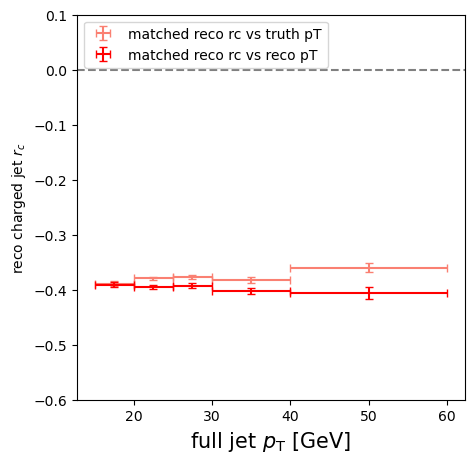

In [19]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [22]:
b1_allreco_array = []
b1_err_allreco_array = []
for i in range(0,5):
    df1_allreco_pts = df1_allreco_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df1_allreco_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df1_allreco_pts['ws'], density=True)
    b1_allreco_array.append(y_reco/sum(y_reco))
    b1_err_allreco_array.append(yerr_reco/sum(y_reco))

In [23]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df1_allreco['pts'], bins=binedges, weights=df1_allreco['ws'])
match, _ = np.histogram(df1_allreco[(df1_allreco.pt!=-9) & (df1_allreco.b!=-9) & (df1_allreco.distance1<0.02) & (df1_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df1_allreco[(df1_allreco.pt!=-9) & (df1_allreco.b!=-9) & (df1_allreco.distance1<0.02) & (df1_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_3335414/2916068059.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [24]:
eff4

array([       nan,        nan, 0.70192534, 0.75046019, 0.77791242,
       0.78965147, 0.80311962])

In [25]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29807466, 0.24953981, 0.22208758, 0.21034853, 0.19688038])

Process sample 2

In [26]:
df2_allfake = applyCut(df2_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df2_match = applyCut(df2_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [27]:
df2_allreco_pts_array = [ df2_allreco[(df2_allreco.pts>15) & (df2_allreco.pts<20)],\
                       df2_allreco[(df2_allreco.pts>20) & (df2_allreco.pts<25)],\
                       df2_allreco[(df2_allreco.pts>25) & (df2_allreco.pts<30)],\
                       df2_allreco[(df2_allreco.pts>30) & (df2_allreco.pts<40)],\
                       df2_allreco[(df2_allreco.pts>40) & (df2_allreco.pts<60)] ]

df2_match_pts_array = [ df2_match[(df2_match.pts>15) & (df2_match.pts<20)],\
                       df2_match[(df2_match.pts>20) & (df2_match.pts<25)],\
                       df2_match[(df2_match.pts>25) & (df2_match.pts<30)],\
                       df2_match[(df2_match.pts>30) & (df2_match.pts<40)],\
                       df2_match[(df2_match.pts>40) & (df2_match.pts<60)] ]

df2_allfake_pts_array = [ df2_allfake[(df2_allfake.pts>15) & (df2_allfake.pts<20)],\
                       df2_allfake[(df2_allfake.pts>20) & (df2_allfake.pts<25)],\
                       df2_allfake[(df2_allfake.pts>25) & (df2_allfake.pts<30)],\
                       df2_allfake[(df2_allfake.pts>30) & (df2_allfake.pts<40)],\
                       df2_allfake[(df2_allfake.pts>40) & (df2_allfake.pts<60)] ]

In [28]:
rc2_allreco_bs_vs_pts_array = []
rc2_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df2_allreco_pts_array)):
    rc2_allreco_bs_vs_pts_array.append(getRcAndErr(df2_allreco_pts_array[i], 'bs')[0])
    rc2_err_allreco_bs_vs_pts_array.append(getRcAndErr(df2_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df2_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df2_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df2_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df2_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df2_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df2_allfake_pts_array[i], 'bs')[1])

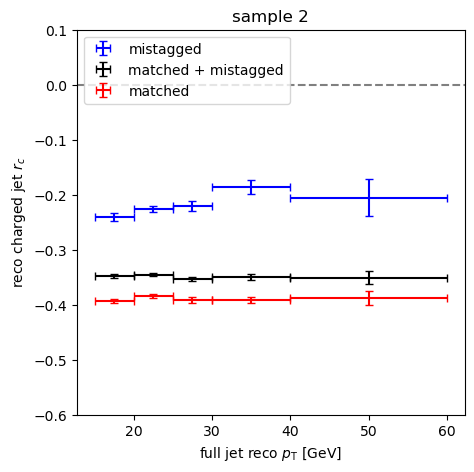

In [29]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc2_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc2_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]')
plt.title('sample 2')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [37]:
b2_allreco_array = []
b2_err_allreco_array = []
for i in range(0,5):
    df2_allreco_pts = df2_allreco_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df2_allreco_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df2_allreco_pts['ws'], density=True)
    b2_allreco_array.append(y_reco/sum(y_reco))
    b2_err_allreco_array.append(yerr_reco/sum(y_reco))

In [38]:
def subtractFake(data, fake_rate, fake_dist):
    corrected = (data - fake_rate * fake_dist)/(1 - fake_rate)
    return corrected

In [39]:
b2_fakesubtracted_array = []
b2_err_fakesubtracted_array = []
rc_fakesubtracted_array = []
rc_err_fakesubtracted_array = []
for i in range(0,5):
    print(i)
    #print(b2_allreco_array[i])
    #print(getRc(data_array[i]))
    b2_fakesubtracted = subtractFake(b2_allreco_array[i], fake_rate_array[i], b1_fake_array[i])
    b2_fakesubtracted_array.append(b2_fakesubtracted)
    b2_err_fakesubtracted = np.sqrt(b2_err_allreco_array[i]**2+(fake_rate_array[i]*b1_err_fake_array[i])**2)
    b2_err_fakesubtracted_array.append(b2_err_fakesubtracted)
    print(b2_fakesubtracted, b2_err_fakesubtracted)
    nos = b2_fakesubtracted[0]
    nss = b2_fakesubtracted[1]
    rc_fakesubtracted = (nss-nos) / (nss+nos)
    rc_fakesubtracted_array.append(rc_fakesubtracted)
    rc_err_fakesubtracted = 2*b2_err_fakesubtracted[0]
    rc_err_fakesubtracted_array.append(rc_err_fakesubtracted)

0
[0.69772172 0.30227828] [0.00371671 0.0025024 ]
1
[0.69270518 0.30729482] [0.00306769 0.00218139]
2
[0.69904902 0.30095098] [0.00418207 0.00302341]
3
[0.69404394 0.30595606] [0.00516802 0.00374297]
4
[0.69975204 0.30024796] [0.01122166 0.00876144]


In [45]:
reweight_array = []
for i in range(0,5):
    reweight_array.append((b2_fakesubtracted_array[i]/sum(b2_fakesubtracted_array[i]))/(b1_match_array[i]/sum(b1_match_array[i])))

In [46]:
reweight_array

[array([1.0031211 , 0.99286948]),
 array([0.9932007 , 1.01567382]),
 array([1.00393756, 0.99097195]),
 array([0.9900316 , 1.02337431]),
 array([0.99501136, 1.01182288])]

Reweight sample 1

In [47]:
r = []
for i in range(0, df1_match.shape[0]):
    if (df1_match.iloc[i]['pts'] > 15 and df1_match.iloc[i]['pts'] < 20):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df1_match.iloc[i]['pts'] > 20 and df1_match.iloc[i]['pts'] < 25):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df1_match.iloc[i]['pts'] > 25 and df1_match.iloc[i]['pts'] < 30):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df1_match.iloc[i]['pts'] > 30 and df1_match.iloc[i]['pts'] < 40):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df1_match.iloc[i]['pts'] > 40 and df1_match.iloc[i]['pts'] < 60):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df1_match.iloc[i]['pts'])
df1_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.15327606289669
anomaly reco pT: 60.49772873075676
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.15032283200955
anomaly reco pT: 63.99508646678217
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 63.19369788337173
anomaly reco pT: 62.74602930593176
anomaly reco pT: 60.03476303183356
anomaly reco pT: 66.83963074901102
anomaly reco pT: 70.61911542903617
anomaly reco pT: 67.1333301990355
anomaly reco pT: 66.47620481622019
anomaly reco pT: 60.54009807311778
anomaly reco pT: 60.55736397596093
anomaly reco pT: 62.79625438717492
anomaly reco pT: 64.06767594033505
anomaly reco pT: 62.35196005363901
anomaly reco pT: 60.050811324850045
anomaly reco pT: 60.946039716285206
anomaly reco pT: 68.10225321467055
anomaly reco pT: 60.9799540425152
anomaly reco pT: 65.16160073216953
anomaly reco pT: 60.0973570676119
anomaly reco pT: 63.822436599165
anomaly reco pT: 74.8368

anomaly reco pT: 68.54885901919411
anomaly reco pT: 61.50396984848846
anomaly reco pT: 64.2182142798535
anomaly reco pT: 60.80583130708745
anomaly reco pT: 62.728856238000006
anomaly reco pT: 69.17229053514693
anomaly reco pT: 63.03810647468715
anomaly reco pT: 62.7859012143824
anomaly reco pT: 66.29737410911332
anomaly reco pT: 63.565336097220666
anomaly reco pT: 63.24551244561167
anomaly reco pT: 62.089369272962
anomaly reco pT: 63.9898512281929
anomaly reco pT: 67.34392454437194
anomaly reco pT: 60.30194368134946
anomaly reco pT: 62.66671837648719
anomaly reco pT: 62.53122089793198
anomaly reco pT: 62.00414824509995
anomaly reco pT: 68.69509447406367
anomaly reco pT: 63.92488173952949
anomaly reco pT: 63.775740988168806
anomaly reco pT: 65.40048930397595
anomaly reco pT: 61.0053162633842
anomaly reco pT: 65.26514207685892
anomaly reco pT: 67.32893261745757
anomaly reco pT: 60.15048352645918
anomaly reco pT: 62.15602295447404
anomaly reco pT: 63.52619916634279
anomaly reco pT: 62.534

anomaly reco pT: 64.36438487503408
anomaly reco pT: 62.94062266284301
anomaly reco pT: 75.46724224373281
anomaly reco pT: 61.80903146481187
anomaly reco pT: 66.14452877031708
anomaly reco pT: 60.79420789744857
anomaly reco pT: 61.510335938526346
anomaly reco pT: 63.60463563764089
anomaly reco pT: 63.84290622372178
anomaly reco pT: 60.24441190326755
anomaly reco pT: 61.89856794874568
anomaly reco pT: 62.71933550193654
anomaly reco pT: 60.37218127058552
anomaly reco pT: 67.35165154282551
anomaly reco pT: 62.938599711603416
anomaly reco pT: 62.01210782743407
anomaly reco pT: 60.09198704471758
anomaly reco pT: 60.17424504803381
anomaly reco pT: 60.10060638205464
anomaly reco pT: 63.40587043188994
anomaly reco pT: 65.75117536986112
anomaly reco pT: 61.4706264844495
anomaly reco pT: 61.18929718786077
anomaly reco pT: 72.35126700760344
anomaly reco pT: 60.24854076145046
anomaly reco pT: 60.06684474591112
anomaly reco pT: 66.72767965295104
anomaly reco pT: 61.75922728597852
anomaly reco pT: 60

anomaly reco pT: 61.73770687585196
anomaly reco pT: 74.15077360023288
anomaly reco pT: 62.990262949112
anomaly reco pT: 60.70855166792012
anomaly reco pT: 75.47290057361973
anomaly reco pT: 61.891682077155146
anomaly reco pT: 63.65350555918853
anomaly reco pT: 60.502287198324034
anomaly reco pT: 62.140137226882494
anomaly reco pT: 60.58973760184473
anomaly reco pT: 68.25018575589665
anomaly reco pT: 60.62101269715139
anomaly reco pT: 63.44703339840572
anomaly reco pT: 61.144122126022445
anomaly reco pT: 62.56903826851902
anomaly reco pT: 65.13405587967877
anomaly reco pT: 65.38701159958929
anomaly reco pT: 62.49970092892863
anomaly reco pT: 60.02989932384669
anomaly reco pT: 60.71988932720338
anomaly reco pT: 65.94239898782774
anomaly reco pT: 62.20716417328564
anomaly reco pT: 61.925664449411656
anomaly reco pT: 61.55536404443391
anomaly reco pT: 65.29376223003007
anomaly reco pT: 60.32571235212267
anomaly reco pT: 62.91918596007402
anomaly reco pT: 60.05665446904023
anomaly reco pT: 

anomaly reco pT: 62.14127124412468
anomaly reco pT: 61.02055470698796
anomaly reco pT: 61.352032860227496
anomaly reco pT: 65.21758701517287
anomaly reco pT: 64.78416612925247
anomaly reco pT: 63.235413288444384
anomaly reco pT: 63.885376662169264
anomaly reco pT: 60.19347808119953
anomaly reco pT: 60.47824318529232
anomaly reco pT: 66.09377021895335
anomaly reco pT: 63.3563445698343
anomaly reco pT: 60.61307890828269
anomaly reco pT: 61.812546681147445
anomaly reco pT: 61.22263259179611
anomaly reco pT: 62.10461901322725
anomaly reco pT: 61.65273190278186
anomaly reco pT: 60.271136906948016
anomaly reco pT: 63.8893393978292
anomaly reco pT: 62.696769386279406
anomaly reco pT: 60.72319983920541
anomaly reco pT: 61.37137376468045
anomaly reco pT: 61.479023951528326
anomaly reco pT: 60.919787226192526
anomaly reco pT: 62.24869291033049
anomaly reco pT: 63.28715507428068
anomaly reco pT: 63.41361560964472
anomaly reco pT: 62.55423716214696
anomaly reco pT: 65.15196497572471
anomaly reco p

anomaly reco pT: 62.25088008768298
anomaly reco pT: 60.74841930645484
anomaly reco pT: 60.373843469716896
anomaly reco pT: 60.69842122566675
anomaly reco pT: 63.40558697565748
anomaly reco pT: 63.71849778104768
anomaly reco pT: 63.16619190421466
anomaly reco pT: 60.73525645953942
anomaly reco pT: 68.98137441094258
anomaly reco pT: 66.30746246808405
anomaly reco pT: 61.78542729895869
anomaly reco pT: 61.4551951419788
anomaly reco pT: 60.001845894717306
anomaly reco pT: 62.42401126121896
anomaly reco pT: 64.44676526803873
anomaly reco pT: 65.71238203317557
anomaly reco pT: 60.80231019786999
anomaly reco pT: 63.796859766694894
anomaly reco pT: 64.7212331231633
anomaly reco pT: 66.9737490149431
anomaly reco pT: 62.49252090258781
anomaly reco pT: 60.4232529391896
anomaly reco pT: 61.52524742781658
anomaly reco pT: 61.857276136187565
anomaly reco pT: 63.173386395884165
anomaly reco pT: 62.5065884493529
anomaly reco pT: 60.09901646616154
anomaly reco pT: 63.64440125353295
anomaly reco pT: 60.

... (16 outputs left out)

anomaly reco pT: 60.21193538425943
anomaly reco pT: 63.43060645862793
anomaly reco pT: 60.18014255656875
anomaly reco pT: 60.258796328273405
anomaly reco pT: 69.49283139846096
anomaly reco pT: 63.81511496320963
anomaly reco pT: 60.91464276148752
anomaly reco pT: 64.33901428237519
anomaly reco pT: 60.70056892926526
anomaly reco pT: 73.12998957510368
anomaly reco pT: 60.08475893363218
anomaly reco pT: 60.717001333457134
anomaly reco pT: 60.02900625164495
anomaly reco pT: 70.14714406281024
anomaly reco pT: 61.7140114860744
anomaly reco pT: 60.32290330572436
anomaly reco pT: 60.91513475624874
anomaly reco pT: 61.83492483324915
anomaly reco pT: 61.50479012982503
anomaly reco pT: 60.21080996539269
anomaly reco pT: 68.35290568359687
anomaly reco pT: 62.91566522543437
anomaly reco pT: 60.44382047641504
anomaly reco pT: 60.66168202796234
anomaly reco pT: 60.79437977906816
anomaly reco pT: 60.79357876934058
anomaly reco pT: 62.789177166826654
anomaly reco pT: 61.31300754083087
anomaly reco pT: 6

anomaly reco pT: 62.39328055412516
anomaly reco pT: 61.88218709334893
anomaly reco pT: 65.70287111854918
anomaly reco pT: 60.74513039059243
anomaly reco pT: 62.49374268883675
anomaly reco pT: 70.08495473771488
anomaly reco pT: 61.83165873964188
anomaly reco pT: 61.45225145866071
anomaly reco pT: 66.31684490439297
anomaly reco pT: 62.042039240803234
anomaly reco pT: 60.17952306669456
anomaly reco pT: 60.11857367301125
anomaly reco pT: 63.69042599426231
anomaly reco pT: 66.47044683987647
anomaly reco pT: 60.611336347378185
anomaly reco pT: 68.40798921990938
anomaly reco pT: 62.59884498120442
anomaly reco pT: 60.4585287785974
anomaly reco pT: 61.27199786672677
anomaly reco pT: 63.90524248470502
anomaly reco pT: 61.98661653439088
anomaly reco pT: 62.41592684385443
anomaly reco pT: 63.72657281313012
anomaly reco pT: 60.67510521196438
anomaly reco pT: 60.20463716213028
anomaly reco pT: 61.679730162669145
anomaly reco pT: 60.80617008343579
anomaly reco pT: 60.65688193134115
anomaly reco pT: 6

anomaly reco pT: 60.62685029904756
anomaly reco pT: 63.04310795454887
anomaly reco pT: 69.14406068938273
anomaly reco pT: 70.52166056114514
anomaly reco pT: 60.00829596619937
anomaly reco pT: 67.46237949806282
anomaly reco pT: 65.45215204708902
anomaly reco pT: 61.58805510280836
anomaly reco pT: 62.80643314341968
anomaly reco pT: 61.93392349275258
anomaly reco pT: 61.47807554592688
anomaly reco pT: 61.408801528901925
anomaly reco pT: 64.45816312963349
anomaly reco pT: 60.81879833062823
anomaly reco pT: 62.501079208919975
anomaly reco pT: 62.81969976511572
anomaly reco pT: 64.53175588834821
anomaly reco pT: 62.58915986881721
anomaly reco pT: 62.61482784628995
anomaly reco pT: 66.65753904743208
anomaly reco pT: 62.22564061464936
anomaly reco pT: 61.267100032309486
anomaly reco pT: 60.48242090877616
anomaly reco pT: 68.43694912640436
anomaly reco pT: 60.303759511477935
anomaly reco pT: 62.32698069264111
anomaly reco pT: 60.00478994632899
anomaly reco pT: 63.403271181078914
anomaly reco pT

/tmp/ipykernel_3335414/1025607542.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1_match['r'] = r #


In [48]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [51]:
df1_match_pt_array = [ df1_match[(df1_match.pt>15) & (df1_match.pt<20)],\
                       df1_match[(df1_match.pt>20) & (df1_match.pt<25)],\
                       df1_match[(df1_match.pt>25) & (df1_match.pt<30)],\
                       df1_match[(df1_match.pt>30) & (df1_match.pt<40)],\
                       df1_match[(df1_match.pt>40) & (df1_match.pt<60)]  ]

In [52]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df1_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df1_match_pt_array[i], 'bs')[1])

In [53]:
print(rc_match_bs_vs_pt_array)

[-0.3921614813523656, -0.3763575756632091, -0.37497028807293215, -0.37609089705590026, -0.3501628762167997]


Obtain truth

In [59]:
df2_alltruth_pt_array = [ df2_alltruth[(df2_alltruth.pt>15) & (df2_alltruth.pt<20)],\
                       df2_alltruth[(df2_alltruth.pt>20) & (df2_alltruth.pt<25)],\
                       df2_alltruth[(df2_alltruth.pt>25) & (df2_alltruth.pt<30)],\
                       df2_alltruth[(df2_alltruth.pt>30) & (df2_alltruth.pt<40)],\
                       df2_alltruth[(df2_alltruth.pt>40) & (df2_alltruth.pt<60)]  ]

In [60]:
rc2_truth_b_vs_pt_array = []
rc2_err_truth_b_vs_pt_array = []
for i in range(0, len(df2_alltruth_pt_array)):
    rc2_truth_b_vs_pt_array.append(getRcAndErr(df2_alltruth_pt_array[i], 'b')[0])
    rc2_err_truth_b_vs_pt_array.append(getRcAndErr(df2_alltruth_pt_array[i], 'b')[1])

Check closure

In [56]:
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
plt.rcParams['font.family'] = 'arial'
plt.rcParams['axes.unicode_minus'] = False

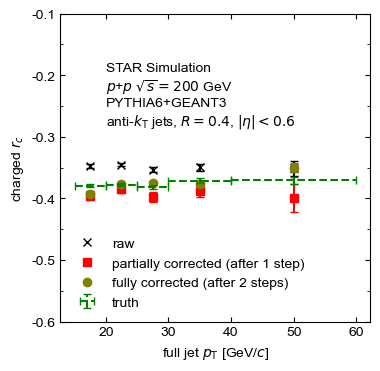

In [63]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc2_allreco_bs_vs_pts_array, yerr=rc2_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_fakesubtracted_array, yerr=rc_err_fakesubtracted_array, capsize=3, color='r', ls='none')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='olive', ls='none')
plt.plot([17.5, 22.5, 27.5, 35, 50], rc2_allreco_bs_vs_pts_array, color='k', ls='none', marker='x', label='raw')
plt.plot([17.5, 22.5, 27.5, 35, 50], rc_fakesubtracted_array, color='r', ls='none', marker='s', label='partially corrected (after 1 step)')
plt.plot([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, color='olive', ls='none', marker='o', label='fully corrected (after 2 steps)')
eb1 = plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc2_truth_b_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc2_err_truth_b_vs_pt_array, capsize=3, color='g', ls='none', label='truth')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV/$c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower left', frameon=False)
plt.text(20, -0.28, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))

In [64]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 15

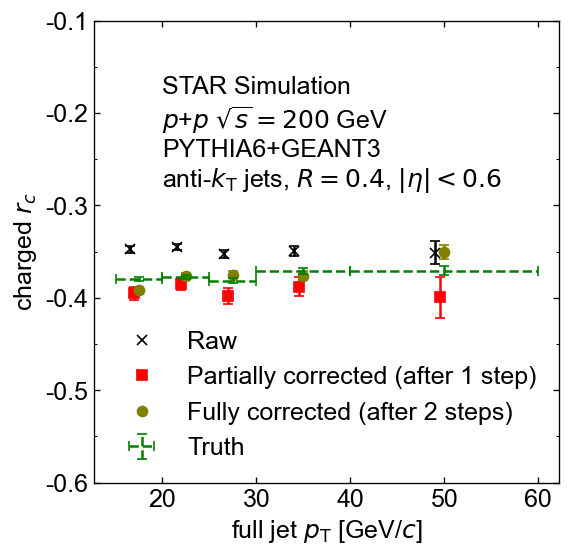

In [67]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([16.5, 21.5, 26.5, 34., 49], rc2_allreco_bs_vs_pts_array, yerr=rc2_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none')
plt.errorbar([17, 22, 27, 34.5, 49.5], rc_fakesubtracted_array, yerr=rc_err_fakesubtracted_array, capsize=3, color='r', ls='none')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='olive', ls='none')
plt.plot([16.5, 21.5, 26.5, 34., 49], rc2_allreco_bs_vs_pts_array, color='k', ls='none', marker='x', label='Raw')
plt.plot([17, 22, 27, 34.5, 49.5], rc_fakesubtracted_array, color='r', ls='none', marker='s', label='Partially corrected (after 1 step)')
plt.plot([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, color='olive', ls='none', marker='o', label='Fully corrected (after 2 steps)')
eb1 = plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc2_truth_b_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc2_err_truth_b_vs_pt_array, capsize=3, color='g', ls='none', label='Truth')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV/$c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower left', frameon=False)
plt.text(20, -0.28, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
plt.savefig('rc_vs_pt_closure_shifted.pdf', bbox_inches='tight')